In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F

import numpy as np
import random
import gymnasium as gym
import matplotlib.pyplot as plt

from collections import deque
from pathlib import Path
from network import *


In [ ]:
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

Device: cpu


In [7]:
def train_baseline():

    env = gym.make("CartPole-v1")

    state_dim = env.observation_space.shape[0]
    action_dim = env.action_space.n

    policy_net = QNetwork(state_dim, action_dim).to(device)
    target_net = QNetwork(state_dim, action_dim).to(device)

    target_net.load_state_dict(policy_net.state_dict())
    target_net.eval()

    optimizer = optim.Adam(
        policy_net.parameters(),
        lr=LEARNING_RATE
    )

    replay_buffer = ReplayBuffer(BUFFER_SIZE)

    episode_rewards = []
    losses = []
    total_steps = 0

    for episode in range(NUM_EPISODES):

        # Sample a new pole length each episode
        length = np.random.uniform(
            MIN_POLE_LENGTH, MAX_POLE_LENGTH
        )

        env.unwrapped.length = length

        state, info = env.reset()
        episode_reward = 0

        for step in range(MAX_STEPS):

            epsilon = get_epsilon(total_steps)

            action = select_action(
                state, policy_net, epsilon
            )

            next_state, reward, terminated, truncated, info = (
                env.step(action)
            )

            done = terminated or truncated

            # Store transition.
            # Only true termination removes future value from TD target.
            replay_buffer.push(
                state,
                action,
                reward,
                next_state,
                terminated
            )

            loss = update_dqn(
                policy_net,
                target_net,
                optimizer,
                replay_buffer
            )

            if loss is not None:
                losses.append(loss)

            state = next_state
            episode_reward += reward
            total_steps += 1

            # Update target network
            if total_steps % TARGET_UPDATE_FREQ == 0:
                target_net.load_state_dict(
                    policy_net.state_dict()
                )

            if done:
                break

        episode_rewards.append(episode_reward)

        if (episode + 1) % 100 == 0:
            avg_reward = np.mean(episode_rewards[-100:])

            print(
                f"Episode {episode + 1}/{NUM_EPISODES} | "
                f"Avg reward: {avg_reward:.2f} | "
                f"Epsilon: {epsilon:.3f}"
            )

    env.close()

    return policy_net, episode_rewards, losses

In [8]:
baseline_model, rewards, losses = train_baseline()

Episode 100/3000 | Avg reward: 33.82 | Epsilon: 0.936
Episode 200/3000 | Avg reward: 37.18 | Epsilon: 0.865
Episode 300/3000 | Avg reward: 47.86 | Epsilon: 0.774
Episode 400/3000 | Avg reward: 56.61 | Epsilon: 0.667
Episode 500/3000 | Avg reward: 56.75 | Epsilon: 0.559
Episode 600/3000 | Avg reward: 65.40 | Epsilon: 0.435
Episode 700/3000 | Avg reward: 73.00 | Epsilon: 0.296
Episode 800/3000 | Avg reward: 118.35 | Epsilon: 0.071
Episode 900/3000 | Avg reward: 245.70 | Epsilon: 0.050
Episode 1000/3000 | Avg reward: 375.58 | Epsilon: 0.050
Episode 1100/3000 | Avg reward: 369.37 | Epsilon: 0.050
Episode 1200/3000 | Avg reward: 309.94 | Epsilon: 0.050
Episode 1300/3000 | Avg reward: 377.70 | Epsilon: 0.050
Episode 1400/3000 | Avg reward: 346.07 | Epsilon: 0.050
Episode 1500/3000 | Avg reward: 330.56 | Epsilon: 0.050
Episode 1600/3000 | Avg reward: 109.57 | Epsilon: 0.050
Episode 1700/3000 | Avg reward: 166.51 | Epsilon: 0.050
Episode 1800/3000 | Avg reward: 307.85 | Epsilon: 0.050
Episode 

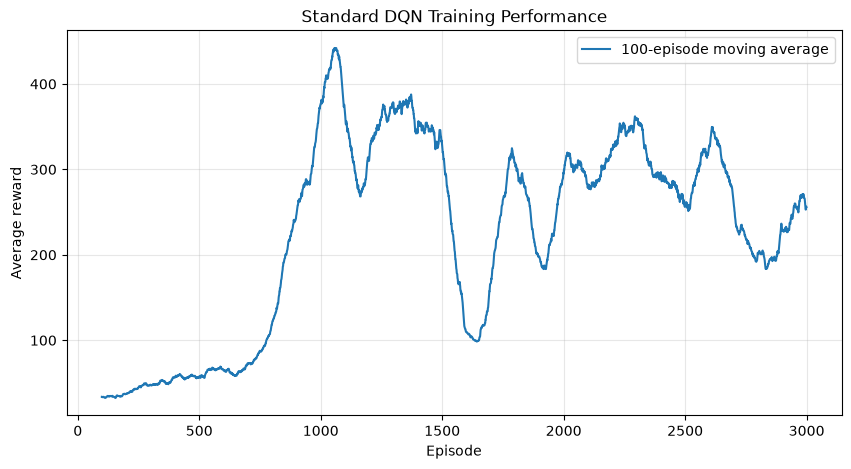

In [9]:
plt.figure(figsize=(10, 5))

moving_average = np.convolve(
    rewards,
    np.ones(100) / 100,
    mode="valid"
)

plt.plot(
    np.arange(99, len(rewards)),
    moving_average,
    label="100-episode moving average"
)

plt.xlabel("Episode")
plt.ylabel("Average reward")
plt.title("Standard DQN Training Performance")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [10]:
Path("weights").mkdir(exist_ok=True)

torch.save(
    baseline_model.cpu().state_dict(),
    "weights/baseline.pth"
)

print("Saved weights/baseline.pth")

Saved weights/baseline.pth
